## Лабораторная работа №1 | Вариант 6

Выполнила: Вельдеватова Наталья Сергеевна

### 1. Numpy

In [108]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [139]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [110]:
np.diag(np.arange(1, 5), k=-1)

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

Вывод:
```
9
10
```

В 1-й строке складываются числа от 0 до 5 не включительно (т.е. от 0 до 4) и прибавляет начальное значение -1.
После 2-й строки имя sum указывает на numpy.sum, в которой второй аргумент задает ось для суммирования

сигнатура:
```
numpy.sum(a, axis=None, dtype=None, out=None, keepdims=<no value>, initial=<no value>, where=<no value>)
```
Поэтому рещультат - сумма от 0 до 4

In [111]:
print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))

10
10


4. Как найти самое часто встречаемое значение между двумя массивами? 

In [112]:
a = np.array([1, 2, 2, 3])
b = np.array([2, 3, 3, 3])

values, counts = np.unique(np.concatenate((a, b)), return_counts=True)
values[np.argmax(counts)]

np.int64(3)

5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [113]:
np.seterr(all="ignore")

arr = np.array([1.0, 0.0])
1.0 / arr

array([ 1., inf])

6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [114]:
def generator():
    for i in range(10):
        yield i

np.fromiter(generator(), dtype=int)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [115]:
nums = np.random.random(10)
sorted_nums = np.sort(nums)
print("Исходный массив: ", nums)
print("Отсортированный: ", sorted_nums)

Исходный массив:  [0.70621396 0.73111739 0.69420753 0.4700762  0.18858395 0.53077251
 0.788866   0.51542917 0.705417   0.93508064]
Отсортированный:  [0.18858395 0.4700762  0.51542917 0.53077251 0.69420753 0.705417
 0.70621396 0.73111739 0.788866   0.93508064]


8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [116]:
xy = np.random.random((10, 2))
x, y = xy.T
polar = np.column_stack((np.hypot(x, y), np.arctan2(y, x)))

print("Декартовы:\n", xy)
print("Полярные:\n", polar)

Декартовы:
 [[0.64011664 0.85525664]
 [0.49257723 0.30494436]
 [0.00537335 0.8361803 ]
 [0.27157629 0.31030193]
 [0.96741417 0.22496672]
 [0.62373337 0.78362894]
 [0.30459728 0.09430128]
 [0.18060439 0.20658871]
 [0.21328823 0.86264023]
 [0.75382413 0.5156095 ]]
Полярные:
 [[1.06827582 0.9282881 ]
 [0.57933012 0.55433039]
 [0.83619757 1.56437035]
 [0.41236024 0.85185299]
 [0.99322717 0.22848358]
 [1.0015576  0.89852672]
 [0.31886084 0.30023458]
 [0.2744027  0.85240716]
 [0.88861692 1.3284071 ]
 [0.91329293 0.5999012 ]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [117]:
dt = np.dtype([("x", np.int32), ("y", np.int32),
               ("r", np.uint8), ("g", np.uint8), ("b", np.uint8)])
pixels = np.array([(0, 0, 255, 0, 0), (1, 0, 0, 255, 0)], dtype=dt)
pixels

array([(0, 0, 255,   0, 0), (1, 0,   0, 255, 0)],
      dtype=[('x', '<i4'), ('y', '<i4'), ('r', 'u1'), ('g', 'u1'), ('b', 'u1')])

10. Как конвертировать тип массив от float32 в int32 in place?

In [118]:
a = np.array([5.2, -4.2, 6.7], dtype=np.float32)
b = a.view(np.int32)
b[:] = a
b

array([ 5, -4,  6], dtype=int32)

Создаём массив с типом float32, затем через view() получаем массив b, который использует ту же память, но имеет тип int32. При присваивании ```b[:] = a``` числа преобразуются в целые с отбрасыванием дробной части. После этого используем b, поскольку содержимое общей памяти изменилось

### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [119]:
import pandas as pd

In [138]:
# Load dataset here
df = pd.read_csv("student_perfomance.csv")
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [121]:
df["Sleep_Hours"].mean()

np.float64(7.029060087785682)

2. Сколько процентов студентов посещают внеклассовые активности?

In [122]:
(df["Extracurricular_Activities"] == "Yes").mean() * 100

np.float64(59.60345088542455)

3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [123]:
avg = df.groupby("Gender")["Exam_Score"].mean()
print("Средние баллы:\n", avg)
print("Девушки сдают лучше:", avg["Female"] > avg["Male"])

Средние баллы:
 Gender
Female    67.244898
Male      67.228894
Name: Exam_Score, dtype: float64
Девушки сдают лучше: True


4. Выведите 25 и 75 перцентили времени сна студентов

In [124]:
df["Sleep_Hours"].quantile([0.25, 0.75])

0.25    6.0
0.75    8.0
Name: Sleep_Hours, dtype: float64

5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [125]:
q1, q3 = df["Sleep_Hours"].quantile([0.25, 0.75])

low = df.loc[df["Sleep_Hours"] <= q1, "Exam_Score"].mean()
high = df.loc[df["Sleep_Hours"] >= q3, "Exam_Score"].mean()

print("Средний балл при сне 6 часов и меньше:", low)
print("Средний балл при сне 8 часов и больше:", high)
print("Те, кто спит больше, сдают лучше:", high > low)

Средний балл при сне 6 часов и меньше: 67.28109243697479
Средний балл при сне 8 часов и больше: 67.18704746580853
Те, кто спит больше, сдают лучше: False


6. Влияет ли физическая активность на результаты экзамена?

In [126]:
avg = df.groupby("Physical_Activity")["Exam_Score"].mean()
corr = df["Physical_Activity"].corr(df["Exam_Score"])

print("Средний балл по уровням физ активности:\n", avg)
print("Корреляция:", corr)

Средний балл по уровням физ активности:
 Physical_Activity
0    67.521739
1    66.969121
2    67.185003
3    67.196071
4    67.313016
5    67.603878
6    68.093750
Name: Exam_Score, dtype: float64
Корреляция: 0.027824436180257397


7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [127]:
edu = df["Parental_Education_Level"]
mask = edu.isin(["College", "Postgraduate"])

high = df.loc[mask, "Exam_Score"].mean()
other = df.loc[edu.notna() & ~mask, "Exam_Score"].mean()

print("Средний балл, если у родителей высшее обр:", high)
print("Средний балл остальных:", other)
print("Первая группа сдаёт лучше:", high > other)

Средний балл, если у родителей высшее обр: 67.57528840315726
Средний балл остальных: 66.89357741234875
Первая группа сдаёт лучше: True


8. Как влияет участие родителей на результаты экзаменов

In [128]:
df.groupby("Parental_Involvement")["Exam_Score"].mean().reindex(["Low", "Medium", "High"])

Parental_Involvement
Low       66.358265
Medium    67.098156
High      68.092767
Name: Exam_Score, dtype: float64

9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [129]:
avg = df.groupby("Family_Income")["Exam_Score"].mean()
avg = avg.reindex(["Low", "Medium", "High"])

print("Средний балл по уровню дохода:\n", avg)
print("При высоком доходе балл выше, чем в обеих остальных группах:",
      avg["High"] > avg["Low"] and avg["High"] > avg["Medium"])

Средний балл по уровню дохода:
 Family_Income
Low       66.848428
Medium    67.334959
High      67.842396
Name: Exam_Score, dtype: float64
При высоком доходе балл выше, чем в обеих остальных группах: True


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [130]:
mask = (df["Family_Income"] == "Low") & (df["Internet_Access"] == "No")
(df.loc[mask, "Exam_Score"] > 70).mean()

np.float64(0.08056872037914692)

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

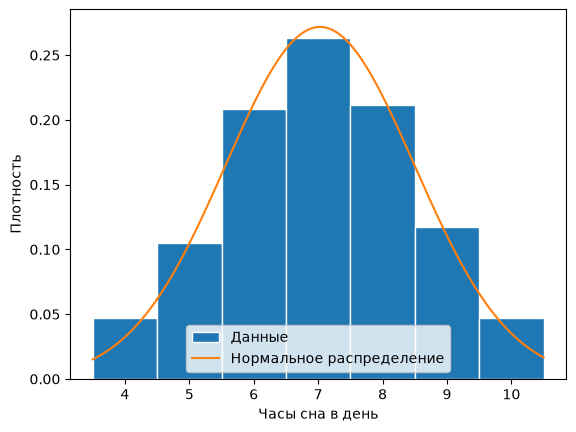

Асимметрия: -0.02380543688615691
Эксцесс: -0.5036974317213616
Распределение примерно похоже на нормальное


In [149]:
import matplotlib.pyplot as plt

s = df["Sleep_Hours"]
bins = np.arange(s.min() - 0.5, s.max() + 1.5)
x = np.linspace(bins[0], bins[-1], 300)
y = np.exp(-0.5 * ((x - s.mean()) / s.std()) ** 2) / (s.std() * np.sqrt(2 * np.pi))

plt.hist(s, bins=bins, density=True, edgecolor="white", label="Данные")
plt.plot(x, y, label="Нормальное распределение")
plt.xlabel("Часы сна в день")
plt.ylabel("Плотность")
plt.legend()
plt.show()

skew = s.skew()
kurt = s.kurt()

print("Асимметрия:", skew)
print("Эксцесс:", kurt)

if abs(skew) < 1 and abs(kurt) < 1:
    print("Распределение примерно похоже на нормальное")
else:
    print("Распределение заметно отличается от нормального")

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

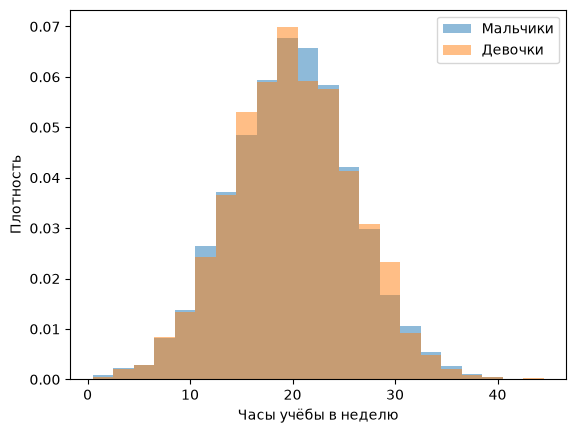

In [132]:
s = df["Hours_Studied"]
bins = np.arange(s.min() - 0.5, s.max() + 2, 2)

for gender, label in [("Male", "Мальчики"), ("Female", "Девочки")]:
    plt.hist(s[df["Gender"] == gender], bins=bins, density=True, alpha=0.5, label=label)

plt.xlabel("Часы учёбы в неделю")
plt.ylabel("Плотность")
plt.legend()
plt.show()

3. Как зависит результат конечного экзамена от результата первого экзамена

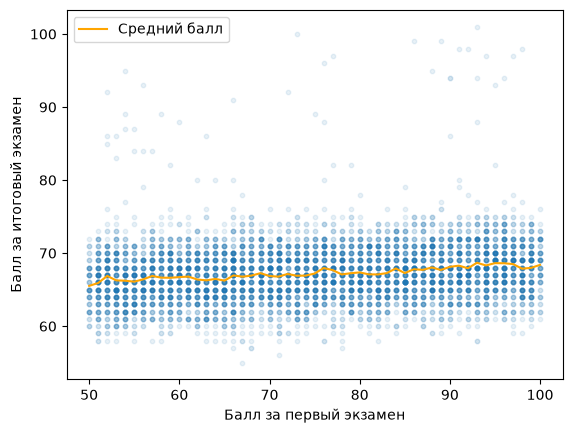

Корреляция: 0.17507908702291092


In [145]:
avg = df.groupby("Previous_Scores")["Exam_Score"].mean()

plt.scatter(df["Previous_Scores"], df["Exam_Score"], s=10, alpha=0.1)
plt.plot(avg.index, avg.values, color="orange", label="Средний балл")
plt.xlabel("Балл за первый экзамен")
plt.ylabel("Балл за итоговый экзамен")
plt.legend()
plt.show()

corr = df["Previous_Scores"].corr(df["Exam_Score"])
print("Корреляция:", corr)

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

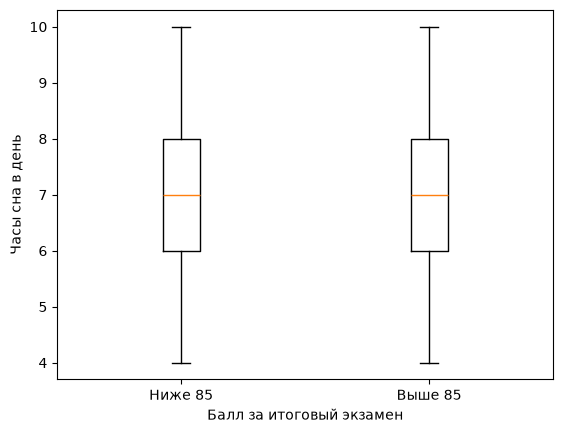

In [134]:
score = df["Exam_Score"]
groups = [df.loc[score < 85, "Sleep_Hours"], df.loc[score > 85, "Sleep_Hours"]]

plt.boxplot(groups)
plt.xticks([1, 2], ["Ниже 85", "Выше 85"])
plt.xlabel("Балл за итоговый экзамен")
plt.ylabel("Часы сна в день")
plt.show()

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

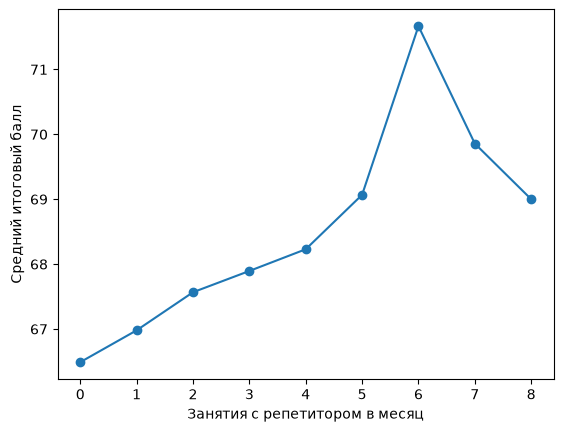

Корреляция: 0.15652518539225316


In [142]:
avg = df.groupby("Tutoring_Sessions")["Exam_Score"].mean()

plt.plot(avg.index, avg.values, marker="o")
plt.xticks(avg.index)
plt.xlabel("Занятия с репетитором в месяц")
plt.ylabel("Средний итоговый балл")
plt.show()

corr = df["Tutoring_Sessions"].corr(df["Exam_Score"])
print("Корреляция:", corr)

6. Как физическая активность влияет на успеваемость?

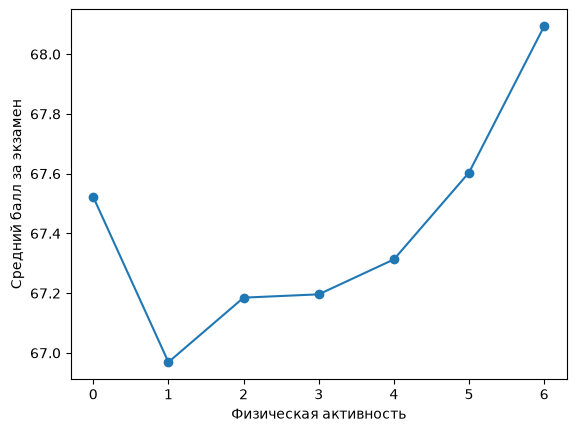

Корреляция: 0.027824436180257397


In [136]:
avg = df.groupby("Physical_Activity")["Exam_Score"].mean()

plt.plot(avg.index, avg.values, marker="o")
plt.xticks(avg.index)
plt.xlabel("Физическая активность")
plt.ylabel("Средний балл за экзамен")
plt.show()

corr = df["Physical_Activity"].corr(df["Exam_Score"])
print("Корреляция:", corr)

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

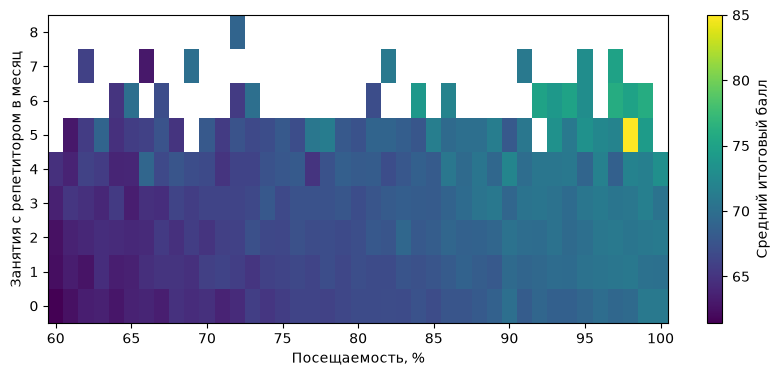

In [137]:
table = df.pivot_table(index="Tutoring_Sessions", columns="Attendance", values="Exam_Score", aggfunc="mean")

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(
    table, origin="lower", aspect="auto", cmap="viridis",
    extent=(table.columns.min() - 0.5, table.columns.max() + 0.5,
            table.index.min() - 0.5, table.index.max() + 0.5)
)

ax.set_yticks(table.index)
ax.set_xlabel("Посещаемость, %")
ax.set_ylabel("Занятия с репетитором в месяц")
fig.colorbar(im, ax=ax, label="Средний итоговый балл")
plt.show()